In [2]:
import rasterio
import numpy as np

cloudy_path = r"E:\Rasengan\Cloud-Removal\data\aligned\patna1\cloudy\BAND3.TIF"
clear_path  = r"E:\Rasengan\Cloud-Removal\data\aligned\patna1\clear\BAND3.TIF"

In [3]:
def inspect_center(path, name):
    with rasterio.open(path) as src:
        h, w = 1024, 1024
        row = (src.height - h) // 2
        col = (src.width - w) // 2

        arr = src.read(
            1,
            window=((row, row + h), (col, col + w))
        ).astype(np.float32)

        valid = np.isfinite(arr)
        if src.nodata is not None:
            valid &= arr != src.nodata

        values = arr[valid]

        print(f"\n{name}")
        print("NoData:", src.nodata)
        print("Center min/max:", arr.min(), arr.max())
        print("Nonzero fraction:", np.mean(arr != 0))

        if values.size:
            print("Valid min/max:", values.min(), values.max())
            print("Mean/std:", values.mean(), values.std())
            print("Percentiles:", np.percentile(values, [1, 25, 50, 75, 99]))
        else:
            print("No valid pixels in center window.")

inspect_center(cloudy_path, "CLOUDY")
inspect_center(clear_path, "CLEAR")


CLOUDY
NoData: None
Center min/max: 135.0 850.0
Nonzero fraction: 1.0
Valid min/max: 135.0 850.0
Mean/std: 324.53973 116.18102
Percentiles: [156.   234.   304.   400.   696.25]

CLEAR
NoData: None
Center min/max: 50.0 195.0
Nonzero fraction: 1.0
Valid min/max: 50.0 195.0
Mean/std: 70.94957 12.609883
Percentiles: [ 57.  62.  67.  75. 114.]


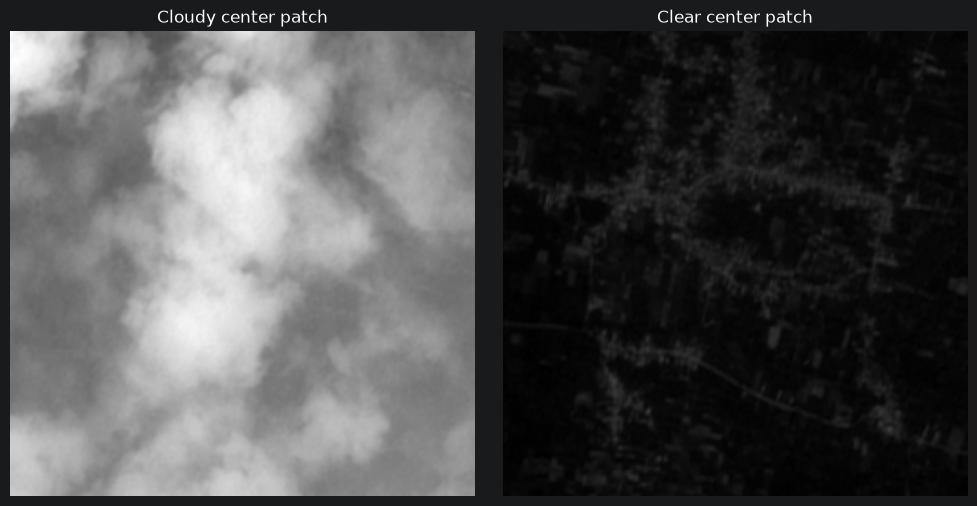

In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

def read_center(path):
    with rasterio.open(path) as src:
        h, w = 256, 256
        row = (src.height - h) // 2
        col = (src.width - w) // 2
        return src.read(
            1, window=((row, row + h), (col, col + w))
        )

cloudy_patch = read_center(cloudy_path)
clear_patch = read_center(clear_path)

# Shared display scale
vmin = min(cloudy_patch.min(), clear_patch.min())
vmax = max(cloudy_patch.max(), clear_patch.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cloudy_patch, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Cloudy center patch")

axes[1].imshow(clear_patch, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Clear center patch")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:


with rasterio.open(cloudy_path) as c, rasterio.open(clear_path) as g:
    print("Cloudy dimensions:", c.width, c.height)
    print("Clear dimensions: ", g.width, g.height)
    print("Cloudy transform:", c.transform)
    print("Clear transform: ", g.transform)
    print("Cloudy CRS:", c.crs)
    print("Clear CRS: ", g.crs)

    for band in (1, 2, 3):
        if band > c.count or band > g.count:
            break

        a = c.read(band, window=((8000, 8256), (8000, 8256))).astype(np.float32)
        b = g.read(band, window=((8000, 8256), (8000, 8256))).astype(np.float32)

        print(f"\nBand {band}")
        print("Cloudy percentiles:", np.percentile(a, [5, 50, 95]))
        print("Clear percentiles: ", np.percentile(b, [5, 50, 95]))

Cloudy dimensions: 17897 16334
Clear dimensions:  17897 16334
Cloudy transform: | 5.00, 0.00, 336518.94|
| 0.00,-5.00, 2916327.50|
| 0.00, 0.00, 1.00|
Clear transform:  | 5.00, 0.00, 336518.94|
| 0.00,-5.00, 2916327.50|
| 0.00, 0.00, 1.00|
Cloudy CRS: EPSG:32645
Clear CRS:  EPSG:32645

Band 1
Cloudy percentiles: [136. 258. 516.]
Clear percentiles:  [58. 68. 99.]


In [6]:
import rasterio
import numpy as np

with rasterio.open(cloudy_path) as c, rasterio.open(clear_path) as g:
    for band in range(1, min(c.count, g.count) + 1):
        a = c.read(band, window=((8000, 8256), (8000, 8256))).astype(np.float32)
        b = g.read(band, window=((8000, 8256), (8000, 8256))).astype(np.float32)

        print(f"\nBand {band}")
        print("Cloudy [P5, P50, P95]:", np.percentile(a, [5, 50, 95]))
        print("Clear  [P5, P50, P95]:", np.percentile(b, [5, 50, 95]))


Band 1
Cloudy [P5, P50, P95]: [136. 258. 516.]
Clear  [P5, P50, P95]: [58. 68. 99.]


In [7]:
import rasterio

for label, path in [
    ("CLOUDY", cloudy_path),
    ("CLEAR", clear_path)
]:
    with rasterio.open(path) as src:
        print(f"\n--- {label} ---")
        print("Band count:", src.count)
        print("Data types:", src.dtypes)
        print("NoData:", src.nodata)
        print("Band descriptions:", src.descriptions)
        print("Scales:", src.scales)
        print("Offsets:", src.offsets)
        print("Metadata:", src.tags())


--- CLOUDY ---
Band count: 1
Data types: ('uint16',)
NoData: None
Band descriptions: (None,)
Scales: (1.0,)
Offsets: (0.0,)
Metadata: {'AREA_OR_POINT': 'Area'}

--- CLEAR ---
Band count: 1
Data types: ('uint16',)
NoData: None
Band descriptions: (None,)
Scales: (1.0,)
Offsets: (0.0,)
Metadata: {'AREA_OR_POINT': 'Area'}


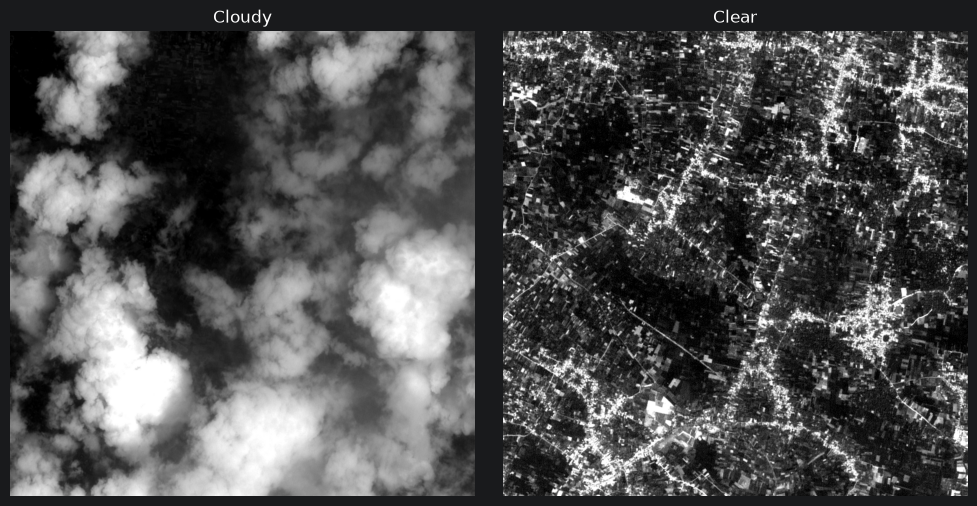

In [8]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open(cloudy_path) as c, rasterio.open(clear_path) as g:
    # Use the same 1024 × 1024 window
    window = ((8000, 9024), (8000, 9024))

    cloudy = c.read(1, window=window).astype(np.float32)
    clear = g.read(1, window=window).astype(np.float32)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

for a, img, title in [
    (ax[0], cloudy, "Cloudy"),
    (ax[1], clear, "Clear")
]:
    lo, hi = np.percentile(img, [2, 98])
    a.imshow(img, cmap="gray", vmin=lo, vmax=hi)
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

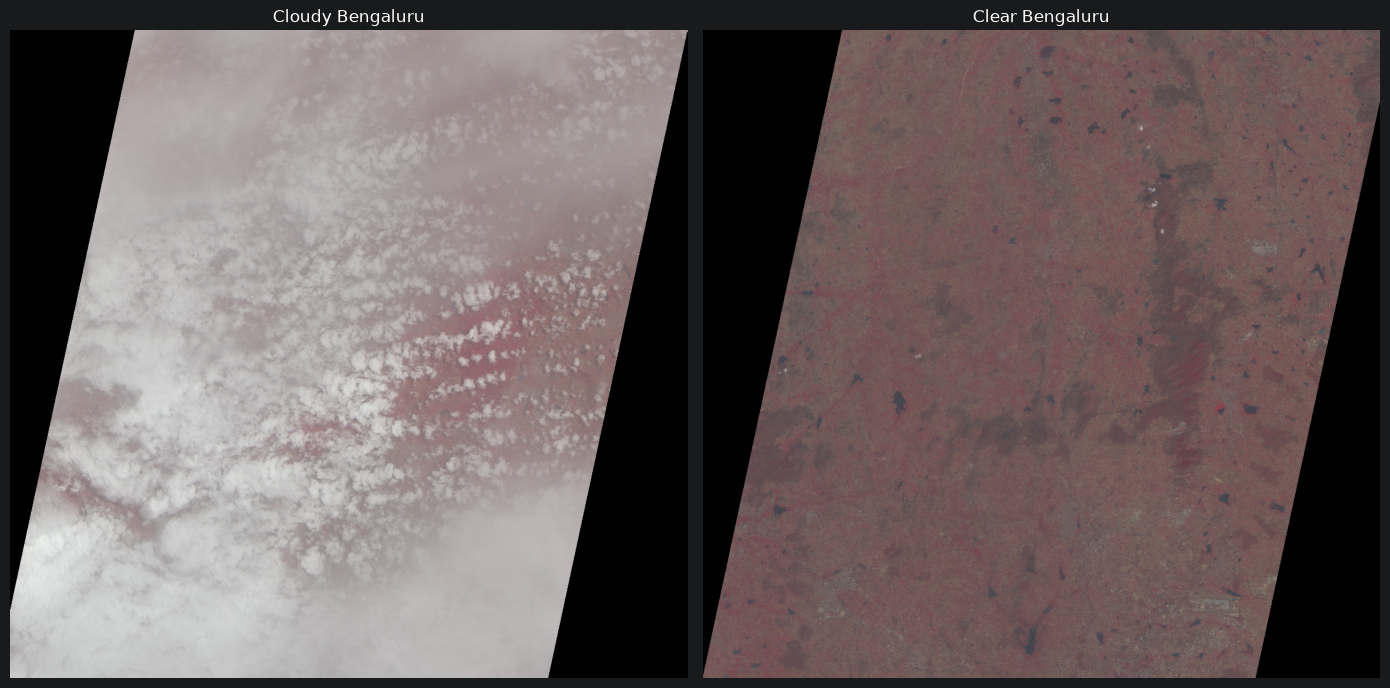

In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"E:\Rasengan\Cloud-Removal\data\new\aligned\bengaluru1")

def load_rgb(folder, max_size=1200):
    bands = []

    for band in ["BAND4.tif", "BAND3.tif", "BAND2.tif"]:
        with rasterio.open(ROOT / folder / band) as src:

            scale = max(
                src.width / max_size,
                src.height / max_size
            )

            height = max(1, int(src.height / scale))
            width = max(1, int(src.width / scale))

            data = src.read(
                1,
                out_shape=(height, width),
                resampling=rasterio.enums.Resampling.nearest
            )

            bands.append(data.astype(np.float32))

    return np.stack(bands, axis=-1)


cloudy = load_rgb("cloudy")
clear = load_rgb("clear")

def display_image(image):
    image = np.clip(image / 1023.0, 0, 1)
    return np.sqrt(image)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(display_image(cloudy))
axes[0].set_title("Cloudy Bengaluru")
axes[0].axis("off")

axes[1].imshow(display_image(clear))
axes[1].set_title("Clear Bengaluru")
axes[1].axis("off")

plt.tight_layout()
plt.show()